# Phase 2: DeepDTA-style CNN baseline

Read saved `metrics.json` and `history.csv` files; this notebook never trains a model. Smoke runs are excluded. MSE uses pKd for DAVIS and the original KIBA score for KIBA. Lower MSE and higher CI are better. Undefined CI (no comparable truths) is shown as missing.

The table includes every seed and the mean and **sample standard deviation** (`ddof=1`) across seeds, for both the CNN and the training-mean predictor. DAVIS includes all and uncensored pairs; KIBA is reported once. Standard deviation is undefined with fewer than two seeds.

The gap is explicitly **warm minus cold-target**, paired by seed and then averaged: a negative MSE gap and a positive CI gap indicate better warm performance. Gaps never mix score scales, subsets or predictors.

In [1]:
import json
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
root = Path(os.environ.get("SC4001_OUTPUT_ROOT", project / "outputs")) / "phase2"
rows, runs = [], []
for path in sorted(root.glob("**/metrics.json")):
    metrics = json.loads(path.read_text())
    if metrics.get("smoke", False) or path.parent.name.endswith("-smoke"):
        continue
    runs.append((path, metrics))
    for predictor, subsets in (("CNN", metrics["test"]), ("training mean", metrics["training_mean_baseline"]["test"])):
        for subset, values in subsets.items():
            rows.append({"dataset": metrics["dataset"], "split": metrics["split"], "subset": subset,
                         "predictor": predictor, "seed": metrics["seed"], "mse": values["mse"], "ci": values["ci"]})
scores = pd.DataFrame(rows)
if scores.empty:
    print("No runs found yet. Run notebooks/kaggle_phase2_gpu.ipynb on a hosted GPU, then copy outputs/phase2/ here.")
else:
    keys = ["dataset", "split", "subset", "predictor"]
    grouped = scores.groupby(keys)[["mse", "ci"]]
    means = grouped.mean().reset_index().assign(seed="mean")
    stds = grouped.std(ddof=1).reset_index().assign(seed="sample std")
    table = pd.concat([scores.assign(seed=scores["seed"].astype(str)), means, stds], ignore_index=True)
    print(table.sort_values(keys + ["seed"]).to_string(index=False, float_format="{:.6f}".format))

dataset             split     subset     predictor       seed      mse       ci
  davis split_cold_target        all           CNN       4001 0.382705 0.800803
  davis split_cold_target        all           CNN       4002 0.392339 0.782023
  davis split_cold_target        all           CNN       4003 0.373276 0.792937
  davis split_cold_target        all           CNN       mean 0.382773 0.791921
  davis split_cold_target        all           CNN sample std 0.009531 0.009431
  davis split_cold_target        all training mean       4001 0.674352 0.500000
  davis split_cold_target        all training mean       4002 0.674352 0.500000
  davis split_cold_target        all training mean       4003 0.674352 0.500000
  davis split_cold_target        all training mean       mean 0.674352 0.500000
  davis split_cold_target        all training mean sample std 0.000000 0.000000
  davis split_cold_target uncensored           CNN       4001 1.015947 0.654252
  davis split_cold_target uncensored    

In [2]:
if not scores.empty:
    selected = scores[scores["split"].isin(["split_warm", "split_cold_target"])]
    paired = selected.pivot(index=["dataset", "subset", "predictor", "seed"], columns="split", values=["mse", "ci"])
    if all((metric, split) in paired for metric in ("mse", "ci") for split in ("split_warm", "split_cold_target")):
        gaps = pd.DataFrame({metric: paired[(metric, "split_warm")] - paired[(metric, "split_cold_target")]
                             for metric in ("mse", "ci")}).dropna(how="all")
        if gaps.empty:
            print("Warm minus cold-target gaps: no matching seeds yet.")
        else:
            print("Warm minus cold-target gaps by seed:")
            print(gaps.to_string(float_format="{:.6f}".format))
            print("Gap mean, sample standard deviation and paired-seed count:")
            print(gaps.groupby(level=["dataset", "subset", "predictor"]).agg(["mean", "std", "count"]).to_string(float_format="{:.6f}".format))
    else:
        print("Warm minus cold-target gaps: both splits are needed.")

Warm minus cold-target gaps by seed:
                                            mse       ci
dataset subset     predictor     seed                   
davis   all        CNN           4001 -0.175056 0.087189
                                 4002 -0.187063 0.107927
                                 4003 -0.148123 0.089923
                   training mean 4001  0.096460 0.000000
                                 4002  0.096460 0.000000
                                 4003  0.096460 0.000000
        uncensored CNN           4001 -0.435331 0.110676
                                 4002 -0.577510 0.122452
                                 4003 -0.421813 0.092905
                   training mean 4001  0.318133 0.000000
                                 4002  0.318133 0.000000
                                 4003  0.318133 0.000000
kiba    all        CNN           4001 -0.189249 0.094467
                                 4002 -0.120323 0.089900
                                 4003 -0.179347 0.0

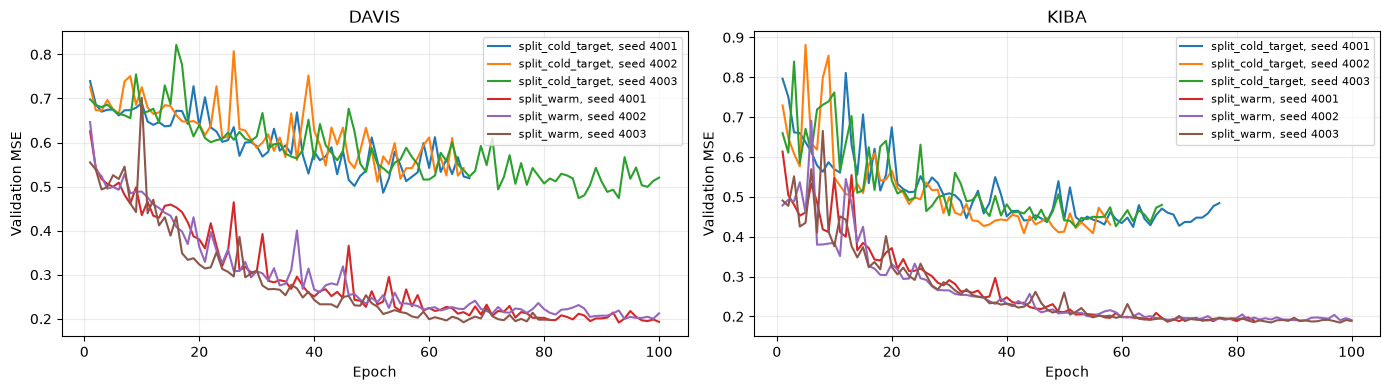

In [3]:
if runs:
    datasets = sorted({metrics["dataset"] for _, metrics in runs})
    figure, axes = plt.subplots(1, len(datasets), figsize=(7 * len(datasets), 4), squeeze=False)
    for axis, dataset in zip(axes[0], datasets):
        for path, metrics in runs:
            if metrics["dataset"] == dataset and (path.parent / "history.csv").exists():
                history = pd.read_csv(path.parent / "history.csv")
                axis.plot(history["epoch"], history["val_mse"], label=f'{metrics["split"]}, seed {metrics["seed"]}')
        axis.set(title=dataset.upper(), xlabel="Epoch", ylabel="Validation MSE")
        if axis.lines:
            axis.legend(fontsize=8)
        else:
            axis.text(0.5, 0.5, "No history.csv files found", ha="center", transform=axis.transAxes)
        axis.grid(alpha=0.25)
    figure.tight_layout()
    plt.show()